# Study time and Portuguese final grades
**Author: AI Foundations (Edward Hickman)**

This analysis uses the real UCI Student Performance Portuguese-language
dataset, collected through school reports and questionnaires at two schools.
It asks whether ordered weekly study-time categories are associated with
final grades, without training a predictive model or claiming causation.

Source: https://archive.ics.uci.edu/dataset/320/student+performance
(Cortez, 2008; CC BY 4.0). The original CSV is beside this notebook.
See `ANALYSIS_PLAN.md` for the analysis decisions and honest timing record.

In [1]:
%matplotlib inline
import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from IPython.display import display

OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
SEED = 20261119
sns.set_theme(style="whitegrid", context="notebook")
STUDY_LABELS = ["<2 hours", "2–5 hours", "5–10 hours", ">10 hours"]
SOURCE_SHA256 = "a7594a11d7771c0efe1a740824e0e833da9c4cad07c39a9766a874575563fb3f"

## 1. Load and screen the data

The file uses semicolons, not commas. Preserve its bytes and all rows;
screen missing values, types, ranges, category codes and exact row matches
before inference. These checks implement the systematic initial-data-analysis
principles in Lusa et al. (2024); this is not a longitudinal analysis.

In [2]:
source = Path("student-por.csv")
assert hashlib.sha256(source.read_bytes()).hexdigest() == SOURCE_SHA256
df = pd.read_csv(source, sep=";")
display(df.head())
print(f"Rows: {df.shape[0]}; columns: {df.shape[1]}")
display(df.dtypes.rename("loaded_dtype").to_frame())

missing = df.isna().sum().rename("missing")
audit = pd.concat([df.dtypes.astype(str).rename("dtype"), missing,
                   df.nunique().rename("distinct_values")], axis=1)
display(audit)
exact_repeats = int(df.duplicated().sum())
assert df.shape == (649, 33)
assert missing.sum() == 0
assert set(df["school"]) == {"GP", "MS"}
assert set(df["studytime"]) == {1, 2, 3, 4}
for name in ["studytime", "G3", "age", "absences"]:
    assert pd.api.types.is_numeric_dtype(df[name])
assert df["G3"].between(0, 20).all()
assert df["age"].between(15, 22).all()
assert df["absences"].ge(0).all()
print(f"Missing cells: {missing.sum()}; repeated full rows: {exact_repeats}")
print("No rows removed, imputed, or recoded; zero grades retained.")
audit.to_csv(OUTPUT / "data_audit.csv")

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Rows: 649; columns: 33


,loaded_dtype
school,str
sex,str
age,int64
address,str
famsize,str
Pstatus,str
Medu,int64
Fedu,int64
Mjob,str
Fjob,str


,dtype,missing,distinct_values
school,str,0,2
sex,str,0,2
age,int64,0,8
address,str,0,2
famsize,str,0,2
Pstatus,str,0,2
Medu,int64,0,5
Fedu,int64,0,5
Mjob,str,0,5
Fjob,str,0,5


Missing cells: 0; repeated full rows: 0
No rows removed, imputed, or recoded; zero grades retained.


## 2. Descriptive statistics

A numeric dtype does not make an ordinal code a measured quantity.
`studytime` is an ordered factor with unequal-width intervals, not a number
of hours. The full `describe` table is an audit; its averages of ordinal
codes are not interpreted. Use counts for those codes and examine grade
means/SD alongside medians/IQR to describe center and spread.

In [3]:
display(df.describe())
numeric_summary = df[["age", "absences", "G1", "G2", "G3"]].describe()
display(numeric_summary)
for name in ["school", "sex", "studytime", "internet", "higher"]:
    print(f"Counts: {name}")
    display(df[name].value_counts().sort_index().rename("n").to_frame())

grouped = df.groupby("studytime")["G3"].agg(
    n="size", mean="mean", sd="std", median="median",
    q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75))
grouped["iqr"] = grouped["q3"] - grouped["q1"]
grouped["study_label"] = STUDY_LABELS
school_groups = df.groupby(["school", "studytime"])["G3"].agg(
    n="size", mean="mean", median="median")
display(grouped)
display(school_groups)
numeric_summary.to_csv(OUTPUT / "numeric_summary.csv")
grouped.to_csv(OUTPUT / "studytime_summary.csv")
school_groups.to_csv(OUTPUT / "school_studytime_summary.csv")

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


,age,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,3.659476,11.399076,11.570108,11.906009
std,1.218138,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,32.000000,19.000000,19.000000,19.000000


Counts: school


,n
school,
GP,423
MS,226


Counts: sex


,n
sex,
F,383
M,266


... (4 outputs left out)

Counts: higher


,n
higher,
no,69
yes,580


,n,mean,sd,median,q1,q3,iqr,study_label
studytime,,,,,,,,
1,212,10.844340,3.218624,11.0,10.0,13.0,3.0,<2 hours
2,305,12.091803,3.243125,12.0,10.0,14.0,4.0,2–5 hours
3,97,13.226804,2.502104,13.0,12.0,15.0,3.0,5–10 hours
4,35,13.057143,3.038410,13.0,11.0,15.0,4.0,>10 hours


n       mean  median
school studytime                        
GP     1          119  11.529412    11.0
       2          206  12.733010    13.0
       3           71  13.563380    14.0
       4           27  13.407407    13.0
MS     1           93   9.967742    10.0
       2           99  10.757576    11.0
       3           26  12.307692    12.0
       4            8  11.875000    12.0

The study-time groups are uneven: most records fall in the two lower
categories, so the >10-hour group has much less information. Grade
distributions, not just averages, are important because students with the
same reported category can have very different outcomes. School counts
also differ; a pooled pattern need not represent the same relationship
within each school.

## 3. Visual models (descriptive charts, not ML models)

### Figure 1. Distribution of final grades
One-grade-wide bins preserve the discrete 0–20 measurement scale.

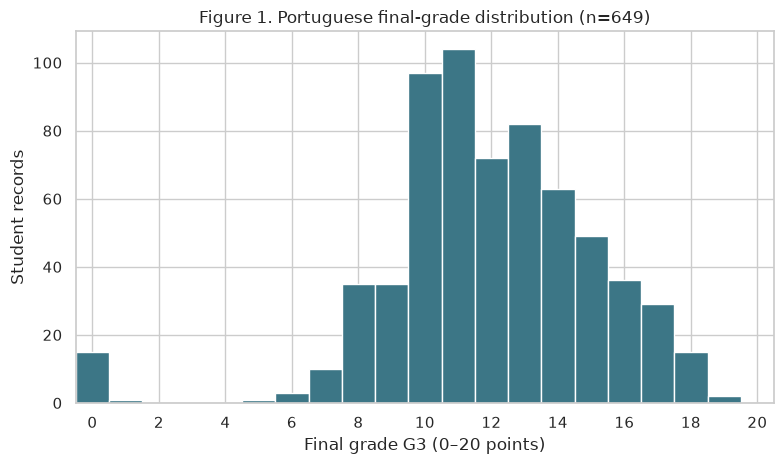

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(df["G3"], bins=np.arange(-.5, 21.5, 1),
        color="#3C7686", edgecolor="white")
ax.set(title="Figure 1. Portuguese final-grade distribution (n=649)",
       xlabel="Final grade G3 (0–20 points)", ylabel="Student records")
ax.set_xticks(np.arange(0, 21, 2))
ax.set_xlim(-.5, 20.5)
fig.tight_layout()
fig.savefig(OUTPUT / "figure_1_grade_distribution.png", dpi=180)
plt.show()
plt.close(fig)

### Figure 2. Grade distributions across ordered study-time groups
Boxes show the median and interquartile range; whiskers extend to
observations within 1.5 IQR of the box. All observations are overlaid
with seeded horizontal jitter; it is visual separation, not added data.

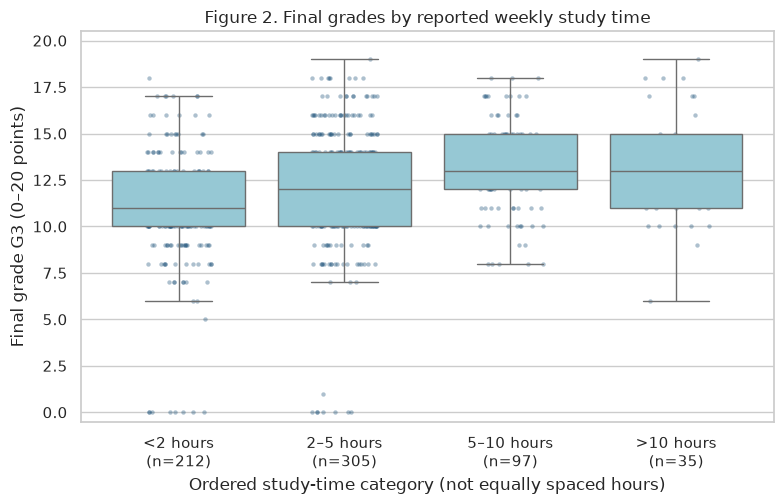

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.2))
sns.boxplot(data=df, x="studytime", y="G3", order=[1, 2, 3, 4],
            color="#8CCEDE", showfliers=False, ax=ax)
rng_plot = np.random.default_rng(SEED)
for position, level in enumerate([1, 2, 3, 4]):
    grades = df.loc[df["studytime"].eq(level), "G3"].to_numpy()
    ax.scatter(position + rng_plot.uniform(-.2, .2, len(grades)), grades,
               color="#154C75", s=10, alpha=.35, linewidths=0)
ax.set_xticks(range(4), [f"{label}\n(n={int(n)})"
                        for label, n in zip(STUDY_LABELS, grouped["n"])])
ax.set(title="Figure 2. Final grades by reported weekly study time",
       xlabel="Ordered study-time category (not equally spaced hours)",
       ylabel="Final grade G3 (0–20 points)", ylim=(-.5, 20.5))
fig.tight_layout()
fig.savefig(OUTPUT / "figure_2_grades_by_studytime.png", dpi=180)
plt.show()
plt.close(fig)

### Figure 3. Study-time pattern within each school
This chart shows cell means, not fitted predictions. Each point is labeled
with its actual sample size; small cells warrant particular caution.
No confidence intervals are shown because this is a descriptive view,
not an uncertainty estimate based on a valid school-sampling model.

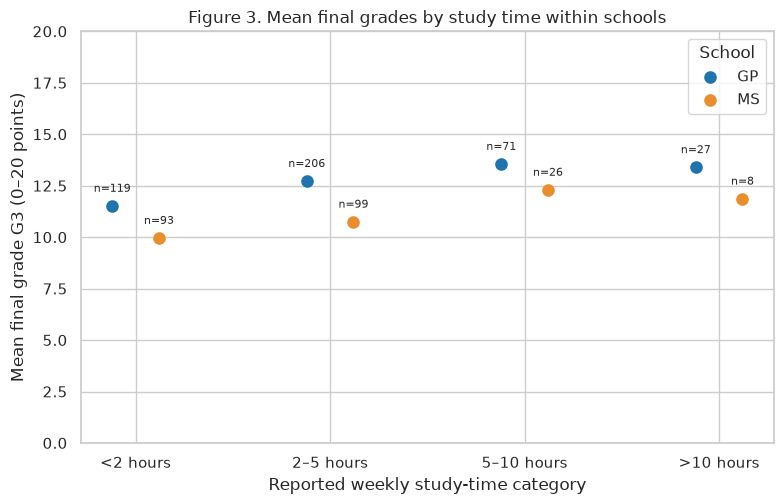

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.2))
for school, shift, color in [("GP", -.12, "#1F74AD"),
                              ("MS", .12, "#E98E2E")]:
    table = school_groups.loc[school].reindex([1, 2, 3, 4])
    xs = np.arange(4) + shift
    ax.scatter(xs, table["mean"], color=color, label=school, s=65)
    for x, mean, n in zip(xs, table["mean"], table["n"]):
        ax.annotate(f"n={int(n)}", (x, mean), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(range(4), STUDY_LABELS)
ax.set(title="Figure 3. Mean final grades by study time within schools",
       xlabel="Reported weekly study-time category",
       ylabel="Mean final grade G3 (0–20 points)", ylim=(0, 20))
ax.legend(title="School")
fig.tight_layout()
fig.savefig(OUTPUT / "figure_3_school_comparison.png", dpi=180)
plt.show()
plt.close(fig)

### Comparison of the three visual models

Figure 1 reveals the grade distribution, including zero grades, but cannot
show the study-time relationship. Figure 2 directly compares the ordered
groups: grade centers generally rise, but distributions overlap substantially,
and the highest-time group does not have the highest mean. Figure 3 separates
school-specific means and cell sizes, making school composition and sparse
groups visible; means alone conceal individual spread. **Figure 2 best
supports the analytical question** because it shows the ordered relationship,
within-group variation and unequal group counts together.

## 4. Primary hypothesis test

**H0:** The population Spearman rank correlation between weekly study-time
category and final grade is zero (rho_s = 0).
**H1:** The population Spearman rank correlation is not zero (rho_s ≠ 0).
Use a two-sided test with alpha = .05.

Spearman correlation measures monotonic association and is appropriate for
ordinal variables (Schober et al., 2018). Average ranks handle ties.
SciPy's p-value is a large-sample approximation, not an exact probability;
it assumes independent observations and suitable sampling. It is not the
probability that H0 is true, nor a causal effect or a measure of practical
importance (American Statistical Association, 2016). Inspect the coefficient
and figures, not only the p-value.

In [7]:
primary = stats.spearmanr(df["studytime"], df["G3"], alternative="two-sided")
x_ranks = stats.rankdata(df["studytime"], method="average")
y_ranks = stats.rankdata(df["G3"], method="average")
independent_rho = np.corrcoef(x_ranks, y_ranks)[0, 1]
assert np.isclose(primary.statistic, independent_rho)
print(f"n = {len(df)}, Spearman rho_s = {primary.statistic:.6f}")
print(f"Two-sided approximate p-value = {primary.pvalue:.8g}; alpha = .05")
print("Reject H0 under the test assumptions." if primary.pvalue < .05
      else "Do not reject H0 under the test assumptions.")
print("A small p-value is not evidence that more study time caused higher grades.")

n = 649, Spearman rho_s = 0.274712
Two-sided approximate p-value = 1.060624e-12; alpha = .05
Reject H0 under the test assumptions.
A small p-value is not evidence that more study time caused higher grades.


## 5. School-adjusted sensitivity diagnostic

School-specific coefficients are descriptive checks, not new primary tests.
For a secondary diagnostic, center the globally ranked variables within
each school and correlate the residual ranks. Shuffle study-time ranks
within schools 19,999 times (seed 20261119). The two-sided Monte Carlo
p-value uses (b+1)/(m+1), never zero (Phipson & Smyth, 2010).

This diagnostic's null is no association under within-school exchangeability;
it differs from the primary zero-rank-correlation null. Permutations hold
school membership fixed but do not resolve classroom clustering, omitted
confounding, or nonrandom sampling. With only two schools, this is not
a cluster-robust population analysis.

In [8]:
def school_rank_permutation(frame, n_resamples=19999, seed=SEED):
    """Correlate school-centered global ranks and permute within schools."""
    x = stats.rankdata(frame["studytime"], method="average")
    y = stats.rankdata(frame["G3"], method="average")
    indices = [np.flatnonzero(frame["school"].to_numpy() == school)
               for school in sorted(frame["school"].unique())]
    for idx in indices:
        x[idx] -= x[idx].mean()
        y[idx] -= y[idx].mean()
    denominator = np.sqrt(np.dot(x, x) * np.dot(y, y))
    observed = float(np.dot(x, y) / denominator)
    rng = np.random.default_rng(seed)
    extreme = 0
    for _ in range(n_resamples):
        numerator = sum(np.dot(rng.permutation(x[idx]), y[idx])
                        for idx in indices)
        extreme += abs(numerator / denominator) >= abs(observed) - 1e-12
    return {"rank_correlation": observed, "extreme_count": int(extreme),
            "n_resamples": n_resamples, "seed": seed,
            "pvalue": (extreme + 1) / (n_resamples + 1)}

school_rhos = {}
for school, sample in df.groupby("school"):
    rho = float(stats.spearmanr(sample["studytime"], sample["G3"]).statistic)
    school_rhos[school] = {"n": len(sample), "rho": rho}
sensitivity = school_rank_permutation(df)
display(pd.DataFrame(school_rhos).T)
display(pd.Series(sensitivity, name="School-adjusted sensitivity"))

,n,rho
GP,423.0,0.267545
MS,226.0,0.177283


rank_correlation    2.467569e-01
extreme_count       0.000000e+00
n_resamples         1.999900e+04
seed                2.026112e+07
pvalue              5.000000e-05
Name: School-adjusted sensitivity, dtype: float64

## 6. Interpretation and limitations

The primary coefficient is positive but far from a perfect monotonic
relationship, and Figure 2 shows substantial overlap. The small approximate
p-value is evidence against the primary null only under the stated
assumptions, not proof of causation or representative sampling.
School adjustment is a sensitivity check, not a fix for every dependency.
Self-reported broad time categories, prior attainment, family resources
and possible classroom dependence can affect interpretation.
Neither students nor schools were randomized; findings do not prescribe
an ideal number of hours or describe all Portuguese students.

In [9]:
summary = {
    "rows": len(df), "columns": len(df.columns),
    "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "missing_cells": int(df.isna().sum().sum()),
    "repeated_full_rows": exact_repeats,
    "grade_mean": float(df["G3"].mean()),
    "grade_sd": float(df["G3"].std(ddof=1)),
    "grade_median": float(df["G3"].median()),
    "grade_q1": float(df["G3"].quantile(.25)),
    "grade_q3": float(df["G3"].quantile(.75)),
    "zero_grades": int(df["G3"].eq(0).sum()),
    "primary_rho": float(primary.statistic),
    "primary_pvalue": float(primary.pvalue),
    "alpha": .05, "school_rhos": school_rhos,
    "sensitivity": sensitivity,
    "studytime_groups": grouped.reset_index().to_dict(orient="records"),
    "school_groups": school_groups.reset_index().to_dict(orient="records"),
}
(OUTPUT / "analysis_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n")
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
(OUTPUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(pd.Series(versions, name="Executed environment"))

python        3.11.18
numpy           2.4.6
pandas          3.1.1
scipy          1.17.1
matplotlib     3.11.2
seaborn        0.13.2
Name: Executed environment, dtype: str

## References and assistance

American Statistical Association. (2016, March 7). *American Statistical
Association releases statement on statistical significance and p-values*.
https://www.amstat.org/asa/files/pdfs/P-ValueStatement.pdf

Cortez, P. (2008). *Student Performance* [Data set]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5TG7T

Lusa, L., Proust-Lima, C., Schmidt, C. O., Lee, K. J., le Cessie, S.,
Baillie, M., Lawrence, F., & Huebner, M., on behalf of TG3 of the STRATOS
Initiative. (2024). Initial data analysis for longitudinal studies to build
a solid foundation for reproducible analysis. *PLOS ONE, 19*(5), e0295726.
https://doi.org/10.1371/journal.pone.0295726

Phipson, B., & Smyth, G. K. (2010). Permutation p-values should never be
zero: Calculating exact p-values when permutations are randomly drawn.
*Statistical Applications in Genetics and Molecular Biology, 9*(1),
Article 39. https://doi.org/10.2202/1544-6115.1585

Schober, P., Boer, C., & Schwarte, L. A. (2018). Correlation coefficients:
Appropriate use and interpretation. *Anesthesia & Analgesia, 126*(5),
1763–1768. https://doi.org/10.1213/ANE.0000000000002864

Replit AI assisted with planning, code preparation, debugging, verification,
and report drafting. All numerical claims must match the executed outputs.
The learner remains responsible for reviewing, understanding and revising
the submission and following the course's AI-use policy.

## 7. Notebook summary

I explored how ordered weekly study-time categories relate to final
Portuguese grades in 649 student records.
Grades generally increased across the study-time categories, but the
highest-time group's mean was not the highest and the distributions
overlapped substantially.
The two-sided Spearman test found evidence of a positive monotonic
association under its assumptions, not evidence of a causal effect.
Important challenges were interpreting unequal-width ordinal categories,
unequal group sizes, and possible dependence within two schools.
I retained all records, documented the data checks, and used a
school-adjusted sensitivity diagnostic rather than treating the pooled
p-value as universally applicable.